# Exploratory data analysis

CMP6202 Artificial Intelligence and Machine Learning. Student ID: s24156365.

This notebook describes the original UCI dataset 697 file. It does not clean the data, split it, encode categories, scale features, or train models.

## Research questions

**RQ1 — approved.** How effectively can Logistic Regression and Random Forest classify students into Dropout, Enrolled, and Graduate categories using enrolment, demographic, socioeconomic, and first- and second-semester academic information?

**RQ2 — proposed, pending approval.** How do first- and second-semester academic performance and progression indicators differ among students who graduate, remain enrolled, or drop out?

**RQ3 — proposed, pending approval.** What relationships can be observed between students' demographic, socioeconomic, and enrolment characteristics and their final academic outcomes?

RQ2 and RQ3 are not approved. The descriptions below say what the file shows that is relevant to each question. They do not treat the proposed questions as accepted.


## 1. Load the original file

The raw file stays unchanged. The only header edit is in memory: the daytime/evening attendance name in the zip extract contains a trailing tab. Duplicate column names are checked after that normalisation.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "raw" / "data.csv").exists():
    ROOT = Path.cwd().parent

RAW_PATH = ROOT / "data" / "raw" / "data.csv"
FIGURE_DIR = ROOT / "figures" / "eda"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

raw_before = RAW_PATH.read_bytes()
df = pd.read_csv(RAW_PATH, sep=";", encoding="utf-8-sig")
original_columns = list(df.columns)
df.columns = [column.replace("\t", "").strip() for column in df.columns]
duplicate_names = df.columns[df.columns.duplicated()].tolist()

if duplicate_names:
    raise ValueError(f"Duplicate column names after header normalisation: {duplicate_names}")
if RAW_PATH.read_bytes() != raw_before:
    raise RuntimeError("The raw dataset changed during loading.")

CLASS_ORDER = ["Dropout", "Enrolled", "Graduate"]
CLASS_COLORS = {"Dropout": "#163A5F", "Enrolled": "#4B5563", "Graduate": "#B7791F"}
GENDER_LABELS = {0: "Female (0)", 1: "Male (1)"}
YES_NO_LABELS = {0: "No (0)", 1: "Yes (1)"}

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#4B5563",
    "axes.labelcolor": "#163A5F",
    "axes.titlecolor": "#163A5F",
    "xtick.color": "#4B5563",
    "ytick.color": "#4B5563",
    "text.color": "#163A5F",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

renamed = [original for original, cleaned in zip(original_columns, df.columns) if original != cleaned]
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print(f"Headers changed in memory only: {renamed}")
print(f"Duplicate names after normalisation: {duplicate_names or 'none'}")
print("Raw file byte length unchanged:", len(raw_before))


Rows: 4424
Columns: 37
Headers changed in memory only: ['Daytime/evening attendance\t']
Duplicate names after normalisation: none
Raw file byte length unchanged: 533230


## 2. Dataset overview

UCI describes 36 input features plus the target `Target`. Integer fields are not all measurements. Category codes, yes/no fields, and an application-order rank stay categorical. Counts, grades, age, and the three macroeconomic fields are the numerical candidates. This follows the UCI variable descriptions recorded in the Phase 2 audit.


In [2]:
CATEGORICAL = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
]
NUMERICAL = [
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",
    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
]
missing_from_guide = [column for column in df.columns if column not in CATEGORICAL + NUMERICAL + ["Target"]]
if missing_from_guide:
    raise ValueError(f"Columns not in the feature guide: {missing_from_guide}")

print("Feature count excluding Target:", df.shape[1] - 1)
print("Categorical candidates:", len(CATEGORICAL))
print("Numerical candidates:", len(NUMERICAL))
overview = pd.DataFrame({
    "pandas_dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(dropna=False),
    "group": [
        "categorical code" if column in CATEGORICAL else "numerical" if column in NUMERICAL else "target"
        for column in df.columns
    ],
})
overview


Feature count excluding Target: 36
Categorical candidates: 18
Numerical candidates: 18


,pandas_dtype,unique_values,group
Marital status,int64,6,categorical code
Application mode,int64,18,categorical code
Application order,int64,8,categorical code
Course,int64,17,categorical code
Daytime/evening attendance,int64,2,categorical code
Previous qualification,int64,17,categorical code
Previous qualification (grade),float64,101,numerical
Nacionality,int64,21,categorical code
Mother's qualification,int64,29,categorical code
Father's qualification,int64,34,categorical code


### How important variables are classified

- `Application order` is an integer rank from first choice toward last choice. It is ordinal, not a continuous measurement.
- Course, marital status, nationality, prior qualification, and parental education and occupation are integer category codes.
- Gender, scholarship, debtor, tuition fees, displaced, international, special educational needs, and daytime/evening attendance are yes/no or two-level codes.
- Age is a count in years. Admission grade and previous-qualification grade are scores on a 0–200 scale.
- Curricular-unit fields are counts, except the two semester grade averages, which are scores on a 0–20 scale. UCI calls those grade fields integers, but this file stores them as decimals.
- Unemployment rate, inflation rate, and GDP are numerical context fields. Their reference dates are not in the file.


## 3. Univariate analysis

The target is shown first because every later comparison uses it. Numerical summaries then cover age, grades, curricular counts, and the macroeconomic fields. Low-cardinality categories are plotted later against the target; high-cardinality codes are summarised in tables so the charts stay readable.


In [3]:
target_counts = df["Target"].value_counts().reindex(CLASS_ORDER)
target_share = (target_counts / len(df) * 100).round(4)
target_table = pd.DataFrame({"count": target_counts, "percentage": target_share})
print(target_table)

numerical_summary = df[NUMERICAL].describe().T[["mean", "std", "min", "50%", "max"]].round(3)
numerical_summary


          count  percentage
Target                     
Dropout    1421     32.1203
Enrolled    794     17.9476
Graduate   2209     49.9322


,mean,std,min,50%,max
Previous qualification (grade),132.613,13.188,95.00,133.100,190.000
Admission grade,126.978,14.482,95.00,126.100,190.000
Age at enrollment,23.265,7.588,17.00,20.000,70.000
Curricular units 1st sem (credited),0.710,2.361,0.00,0.000,20.000
Curricular units 1st sem (enrolled),6.271,2.480,0.00,6.000,26.000
Curricular units 1st sem (evaluations),8.299,4.179,0.00,8.000,45.000
Curricular units 1st sem (approved),4.707,3.094,0.00,5.000,26.000
Curricular units 1st sem (grade),10.641,4.844,0.00,12.286,18.875
Curricular units 1st sem (without evaluations),0.138,0.691,0.00,0.000,12.000
Curricular units 2nd sem (credited),0.542,1.919,0.00,0.000,19.000


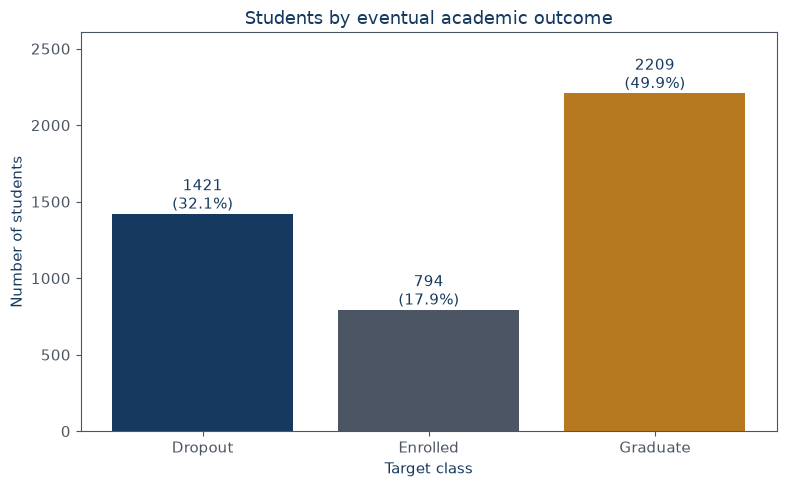

D:\Juraid\5th semester\AI & ML\CMP6202-AI-ML\figures\eda\figure_01_target_distribution.png


In [4]:
figure_path = FIGURE_DIR / "figure_01_target_distribution.png"
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    CLASS_ORDER,
    target_counts.loc[CLASS_ORDER],
    color=[CLASS_COLORS[label] for label in CLASS_ORDER],
)
ax.set_title("Students by eventual academic outcome")
ax.set_xlabel("Target class")
ax.set_ylabel("Number of students")
for bar, label in zip(bars, CLASS_ORDER):
    count = int(target_counts.loc[label])
    share = target_share.loc[label]
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{count}\n({share:.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, target_counts.max() * 1.18)
fig.tight_layout()
fig.savefig(figure_path, dpi=200)
plt.show()
print(figure_path)


### Target distribution

The file has 4,424 students. Graduate is the largest class at 2,209 students (49.9322%). Dropout has 1,421 students (32.1203%). Enrolled has 794 students (17.9476%). The classes are unequal, so a later accuracy score could look strong while saying little about Dropout or Enrolled. This is a description of the sample, not a claim about a model.


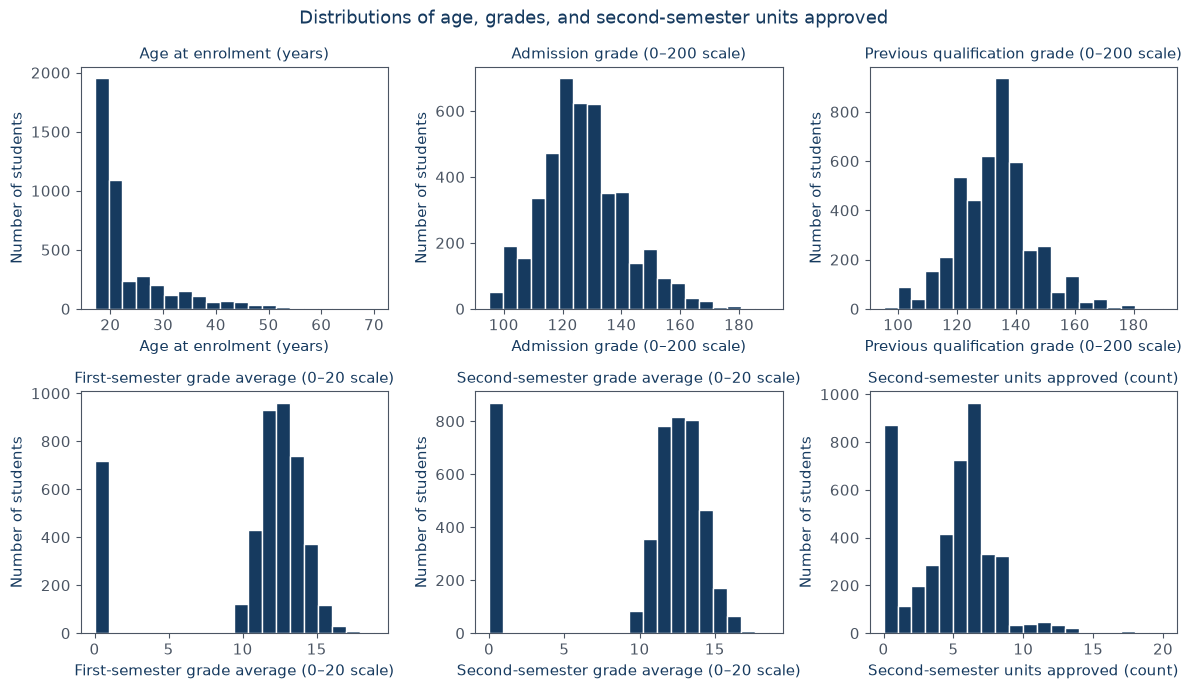

                                        mean     std   min      50%      max
Age at enrollment                     23.265   7.588  17.0   20.000   70.000
Admission grade                      126.978  14.482  95.0  126.100  190.000
Previous qualification (grade)       132.613  13.188  95.0  133.100  190.000
Curricular units 1st sem (grade)      10.641   4.844   0.0   12.286   18.875
Curricular units 2nd sem (grade)      10.230   5.211   0.0   12.200   18.571
Curricular units 2nd sem (approved)    4.436   3.015   0.0    5.000   20.000


In [5]:
distribution_columns = [
    ("Age at enrollment", "Age at enrolment (years)"),
    ("Admission grade", "Admission grade (0–200 scale)"),
    ("Previous qualification (grade)", "Previous qualification grade (0–200 scale)"),
    ("Curricular units 1st sem (grade)", "First-semester grade average (0–20 scale)"),
    ("Curricular units 2nd sem (grade)", "Second-semester grade average (0–20 scale)"),
    ("Curricular units 2nd sem (approved)", "Second-semester units approved (count)"),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (column, label) in zip(axes.ravel(), distribution_columns):
    ax.hist(df[column], bins=20, color="#163A5F", edgecolor="white")
    ax.set_title(label, fontsize=11)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of students")
fig.suptitle("Distributions of age, grades, and second-semester units approved", fontsize=13)
fig.tight_layout()
figure_path = FIGURE_DIR / "figure_02_numerical_distributions.png"
fig.savefig(figure_path, dpi=200)
plt.show()
print(numerical_summary.loc[[item[0] for item in distribution_columns]])


### Numerical distributions

Age at enrolment has a median of 20 years and a mean of 23.265. The range is 17 to 70, so the distribution has a longer right tail.

Admission grades have a mean of 126.978 on the 0–200 scale (minimum 95, maximum 190). Previous-qualification grades have a mean of 132.613 on the same scale.

Both semester grade averages are centred near 10 to 12 on the 0–20 scale, with a spike at 0. Every first-semester grade of 0 occurs with 0 approved units (718 rows). Every second-semester grade of 0 also occurs with 0 approved units (870 rows). The file records these as 0 rather than missing. UCI does not say whether 0 is a real average or a placeholder for students with no graded units. That distinction is left open.

Credited units and units without evaluations have medians of 0. Most students have none of those counts. Enrolled and evaluated units are more spread out, with medians of 6 and 8.

Unemployment rate, inflation rate, and GDP take only 10, 9, and 10 distinct values. They behave like a small set of repeated context figures rather than a student-specific measurement.


## 4. Academic features and the target

These comparisons describe differences among the three outcome groups. They do not show that a grade or a unit count caused the outcome. Semester results are available by the approved prediction point, which is after the second semester. The target is the later outcome.


In [6]:
academic_columns = [
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 1st sem (credited)",
    "Curricular units 2nd sem (credited)",
    "Curricular units 1st sem (without evaluations)",
    "Curricular units 2nd sem (without evaluations)",
    "Admission grade",
    "Previous qualification (grade)",
]
academic_means = df.groupby("Target")[academic_columns].mean().reindex(CLASS_ORDER).round(3)
academic_medians = df.groupby("Target")[academic_columns].median().reindex(CLASS_ORDER).round(3)
print("Means")
print(academic_means.T)
print("Medians")
print(academic_medians.T)

zero_grade = pd.DataFrame({
    "first_semester_grade_is_zero": df.groupby("Target")["Curricular units 1st sem (grade)"].apply(lambda s: (s == 0).mean()).reindex(CLASS_ORDER),
    "second_semester_grade_is_zero": df.groupby("Target")["Curricular units 2nd sem (grade)"].apply(lambda s: (s == 0).mean()).reindex(CLASS_ORDER),
}).round(4)
for semester in ("1st", "2nd"):
    grade = df[f"Curricular units {semester} sem (grade)"]
    approved = df[f"Curricular units {semester} sem (approved)"]
    zero_rows = int((grade == 0).sum())
    zero_and_none_approved = int(((grade == 0) & (approved == 0)).sum())
    print(f"{semester} semester: {zero_rows} zero grades, {zero_and_none_approved} of them also have 0 approved units")
zero_grade


Means
Target                                          Dropout  Enrolled  Graduate
Curricular units 1st sem (grade)                  7.257    11.125    12.644
Curricular units 2nd sem (grade)                  5.899    11.117    12.697
Curricular units 1st sem (enrolled)               5.821     5.965     6.670
Curricular units 2nd sem (enrolled)               5.780     5.938     6.628
Curricular units 1st sem (evaluations)            7.752     9.341     8.277
Curricular units 2nd sem (evaluations)            7.174     9.436     8.142
Curricular units 1st sem (approved)               2.552     4.319     6.232
Curricular units 2nd sem (approved)               1.940     4.058     6.177
Curricular units 1st sem (credited)               0.609     0.508     0.847
Curricular units 2nd sem (credited)               0.450     0.359     0.667
Curricular units 1st sem (without evaluations)    0.192     0.178     0.088
Curricular units 2nd sem (without evaluations)    0.238     0.188     0.081
Admiss

,first_semester_grade_is_zero,second_semester_grade_is_zero
Target,,
Dropout,0.4011,0.5116
Enrolled,0.0894,0.0856
Graduate,0.0349,0.0340


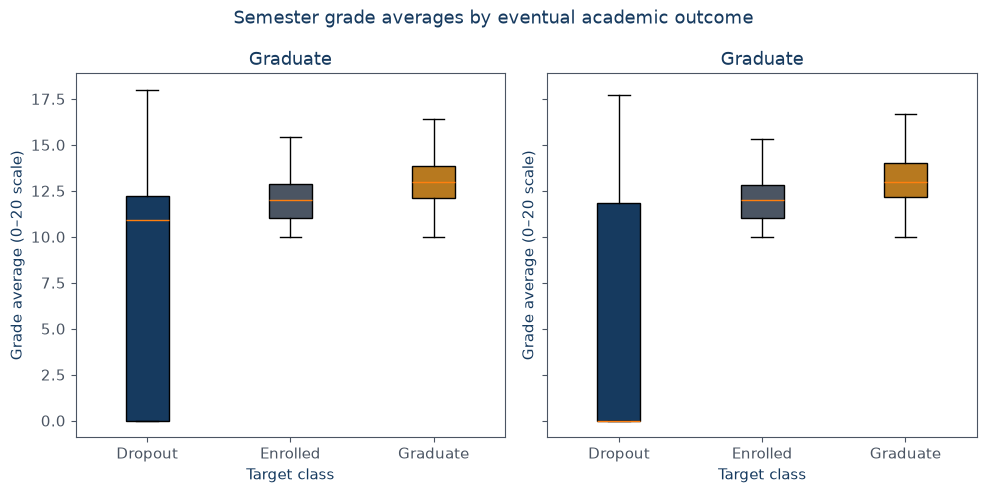

In [7]:
grade_columns = [
    ("Curricular units 1st sem (grade)", "First-semester grade average (0–20)"),
    ("Curricular units 2nd sem (grade)", "Second-semester grade average (0–20)"),
]
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for ax, (column, label) in zip(axes, grade_columns):
    data = [df.loc[df["Target"] == label, column] for label in CLASS_ORDER]
    box = ax.boxplot(data, tick_labels=CLASS_ORDER, patch_artist=True, showfliers=False)
    for patch, label in zip(box["boxes"], CLASS_ORDER):
        patch.set_facecolor(CLASS_COLORS[label])
    ax.set_title(label)
    ax.set_xlabel("Target class")
    ax.set_ylabel("Grade average (0–20 scale)")
fig.suptitle("Semester grade averages by eventual academic outcome", fontsize=13)
fig.tight_layout()
figure_path = FIGURE_DIR / "figure_03_semester_grades_by_target.png"
fig.savefig(figure_path, dpi=200)
plt.show()


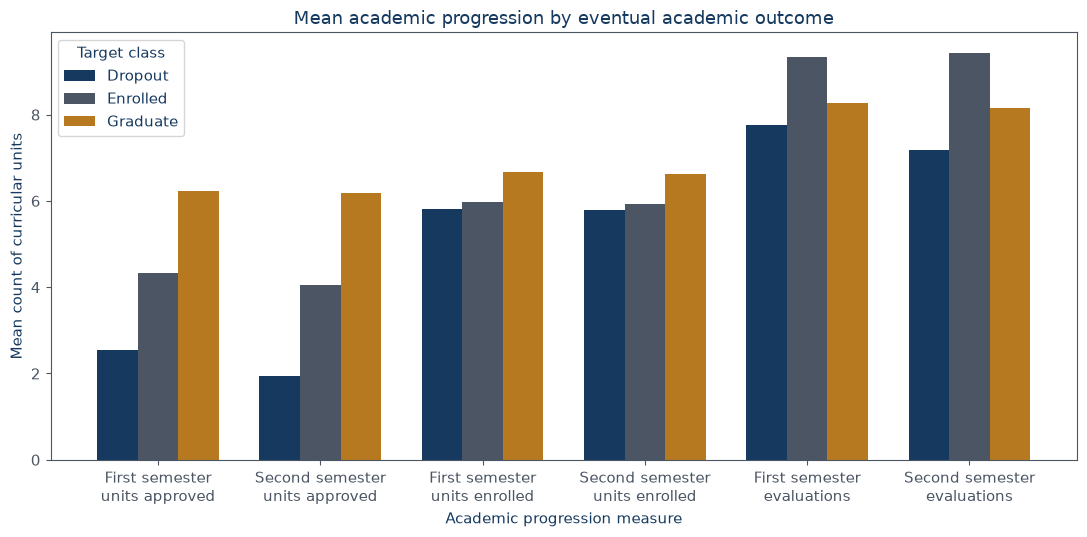

In [8]:
progression_columns = [
    ("Curricular units 1st sem (approved)", "First semester\nunits approved"),
    ("Curricular units 2nd sem (approved)", "Second semester\nunits approved"),
    ("Curricular units 1st sem (enrolled)", "First semester\nunits enrolled"),
    ("Curricular units 2nd sem (enrolled)", "Second semester\nunits enrolled"),
    ("Curricular units 1st sem (evaluations)", "First semester\nevaluations"),
    ("Curricular units 2nd sem (evaluations)", "Second semester\nevaluations"),
]
means = df.groupby("Target")[[column for column, _ in progression_columns]].mean().reindex(CLASS_ORDER)
x = np.arange(len(progression_columns))
width = 0.25
fig, ax = plt.subplots(figsize=(11, 5.5))
for offset, label in enumerate(CLASS_ORDER):
    ax.bar(
        x + (offset - 1) * width,
        means.loc[label],
        width=width,
        label=label,
        color=CLASS_COLORS[label],
    )
ax.set_xticks(x)
ax.set_xticklabels([label for _, label in progression_columns])
ax.set_ylabel("Mean count of curricular units")
ax.set_xlabel("Academic progression measure")
ax.set_title("Mean academic progression by eventual academic outcome")
ax.legend(title="Target class")
fig.tight_layout()
figure_path = FIGURE_DIR / "figure_04_academic_progression_by_target.png"
fig.savefig(figure_path, dpi=200)
plt.show()


### Academic patterns

Mean units approved separate the classes sharply. Dropout students approved 2.552 units in the first semester and 1.940 in the second. Enrolled students approved 4.319 and 4.058. Graduates approved 6.232 and 6.177. Median second-semester units approved are 0 for Dropout, 4 for Enrolled, and 6 for Graduate.

Mean semester grades follow the same order. First-semester means are 7.257 for Dropout, 11.125 for Enrolled, and 12.644 for Graduate. Second-semester means are 5.899, 11.117, and 12.697. A grade of 0 is much more common for Dropout: 40.11% in semester 1 and 51.16% in semester 2, compared with 3.49% and 3.40% for graduates.

Units enrolled differ less than units approved. Mean second-semester enrolment is 5.780 for Dropout, 5.938 for Enrolled, and 6.628 for Graduate. Evaluations are not ordered in the same way: Enrolled students have the highest mean evaluation counts (9.341 and 9.436), above both Dropout and Graduate.

Admission-grade means are 124.961, 125.534, and 128.794. Previous-qualification means are 131.114, 131.208, and 134.083. Graduates are higher on both entry grades, but the gap is smaller than the gap in units approved during the course.

These are group differences in this file. They do not establish that approving more units caused graduation.


## 5. Demographic, socioeconomic, and enrolment features

Gender labels follow UCI: 1 is male and 0 is female. Scholarship, debtor, and tuition fields use 1 for yes and 0 for no. Parental education and occupation stay as their UCI integer codes. The largest codes are reported; rare codes are not given their own chart because several marital-status and special-needs groups contain only a handful of students.


            mean  median  min  max
Target                            
Dropout   26.069    23.0   18   70
Enrolled  22.369    20.0   17   54
Graduate  21.784    19.0   17   62


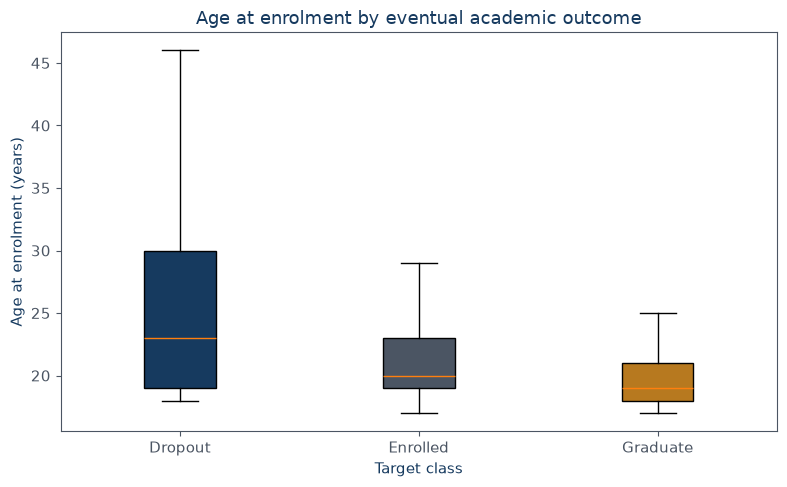

In [9]:
age_by_target = df.groupby("Target")["Age at enrollment"].agg(["mean", "median", "min", "max"]).reindex(CLASS_ORDER).round(3)
print(age_by_target)

fig, ax = plt.subplots(figsize=(8, 5))
data = [df.loc[df["Target"] == label, "Age at enrollment"] for label in CLASS_ORDER]
box = ax.boxplot(data, tick_labels=CLASS_ORDER, patch_artist=True, showfliers=False)
for patch, label in zip(box["boxes"], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[label])
ax.set_title("Age at enrolment by eventual academic outcome")
ax.set_xlabel("Target class")
ax.set_ylabel("Age at enrolment (years)")
fig.tight_layout()
figure_path = FIGURE_DIR / "figure_05_age_by_target.png"
fig.savefig(figure_path, dpi=200)
plt.show()


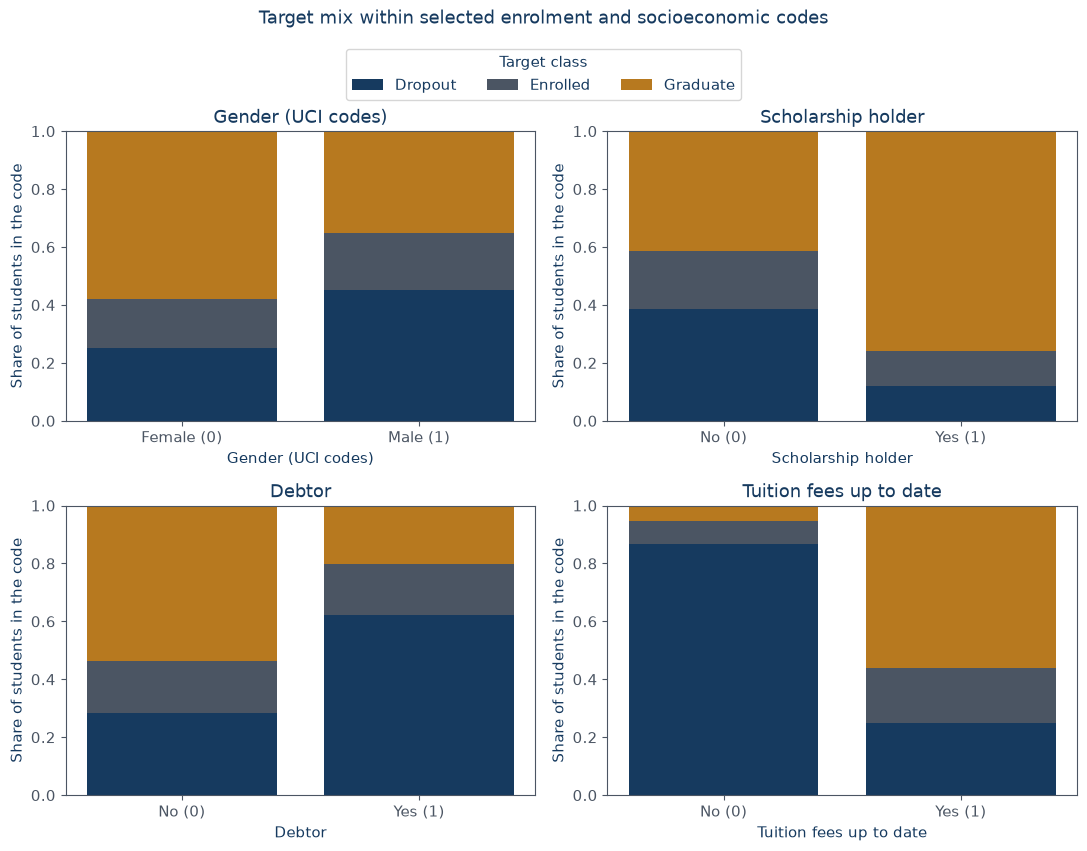

Gender
Target  Dropout  Enrolled  Graduate
Gender                             
0           720       487      1661
1           701       307       548
Target  Dropout  Enrolled  Graduate
Gender                             
0         25.10     16.98     57.91
1         45.05     19.73     35.22
Scholarship holder
Target              Dropout  Enrolled  Graduate
Scholarship holder                             
0                      1287       664      1374
1                       134       130       835
Target              Dropout  Enrolled  Graduate
Scholarship holder                             
0                     38.71     19.97     41.32
1                     12.19     11.83     75.98
Debtor
Target  Dropout  Enrolled  Graduate
Debtor                             
0          1109       704      2108
1           312        90       101
Target  Dropout  Enrolled  Graduate
Debtor                             
0         28.28     17.95     53.76
1         62.03     17.89     20.08
Tuition

In [10]:
category_specs = [
    ("Gender", GENDER_LABELS, "Gender (UCI codes)"),
    ("Scholarship holder", YES_NO_LABELS, "Scholarship holder"),
    ("Debtor", YES_NO_LABELS, "Debtor"),
    ("Tuition fees up to date", YES_NO_LABELS, "Tuition fees up to date"),
]
share_frames = []
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (column, labels, title) in zip(axes.ravel(), category_specs):
    counts = pd.crosstab(df[column], df["Target"]).reindex(columns=CLASS_ORDER)
    shares = counts.div(counts.sum(axis=1), axis=0)
    share_frames.append((column, counts, (shares * 100).round(2)))
    x = np.arange(len(shares.index))
    bottom = np.zeros(len(shares.index))
    for class_label in CLASS_ORDER:
        values = shares[class_label].to_numpy()
        ax.bar(x, values, bottom=bottom, color=CLASS_COLORS[class_label], label=class_label)
        bottom = bottom + values
    ax.set_xticks(x)
    ax.set_xticklabels([labels.get(value, str(value)) for value in shares.index])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Share of students in the code")
    ax.set_xlabel(title)
    ax.set_title(title)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, title="Target class", loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Target mix within selected enrolment and socioeconomic codes", y=1.06, fontsize=13)
fig.tight_layout()
figure_path = FIGURE_DIR / "figure_06_selected_categoricals_by_target.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()
for column, counts, shares in share_frames:
    print(column)
    print(counts)
    print(shares)


In [11]:
for column in ["Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]:
    top_codes = df[column].value_counts().head(5).index
    subset = df[df[column].isin(top_codes)]
    shares = pd.crosstab(subset[column], subset["Target"], normalize="index").reindex(columns=CLASS_ORDER)
    counts = df[column].value_counts().loc[top_codes]
    print(column)
    print(pd.DataFrame({"students": counts, "graduate_percent": (shares["Graduate"] * 100).round(1), "dropout_percent": (shares["Dropout"] * 100).round(1)}))


Mother's qualification
                        students  graduate_percent  dropout_percent
Mother's qualification                                             
1                           1069              52.9             28.1
3                            438              45.2             31.7
19                           953              53.1             28.4
37                          1009              45.3             38.0
38                           562              58.9             24.9
Father's qualification
                        students  graduate_percent  dropout_percent
Father's qualification                                             
1                            904              49.9             31.1
3                            282              46.1             31.9
19                           968              53.8             27.3
37                          1209              47.8             35.7
38                           702              58.1             23.8
Mo

### Demographic and socioeconomic patterns

Dropout students are older at enrolment on average: mean age 26.069 years, median 23. Enrolled students have a mean of 22.369 and a median of 20. Graduates have a mean of 21.784 and a median of 19. The age correlation with second-semester grade is -0.173. That is a weak negative association, not an explanation of the outcome.

Gender code 0 (female in the UCI description) covers 2,868 students, of whom 57.91% are graduates and 25.10% are dropouts. Gender code 1 (male) covers 1,556 students, of whom 35.22% are graduates and 45.05% are dropouts.

Among the 1,099 scholarship holders, 75.98% are graduates and 12.19% are dropouts. Among the 3,325 students without a scholarship, 41.32% are graduates and 38.71% are dropouts.

Debtor code 1 covers 503 students. Of those, 62.03% are dropouts and 20.08% are graduates. Among students who are not debtors, 28.28% are dropouts and 53.76% are graduates.

Tuition fees not up to date covers 528 students. Of those, 86.55% are dropouts and 5.49% are graduates. Among students whose fees are up to date, 24.74% are dropouts and 55.95% are graduates. These debtor and tuition associations are large. UCI does not state when the fields were measured, so they are not yet treated as safe predictors for a decision made at the end of the second semester.

The five most common parental qualification and occupation codes show graduate shares mostly between about 43% and 59%. That spread is smaller than the spread for tuition status, scholarship, or units approved. Rare marital-status codes are too small for a stable comparison: widowed has 4 students, legally separated has 6, and facto union has 25. International students number 110, and students with special educational needs number 51. Their target mixes are close to the larger groups, but the small counts make those comparisons fragile.

Daytime attendance (code 1, 3,941 students) has a 30.80% dropout share. Evening attendance (code 0, 483 students) has a 42.86% dropout share.


## 6. Relationships among numerical features

The heatmap uses the numerical candidates only. Category codes are excluded so that integer labels are not treated as distances. Correlation here means a linear association in this file. It does not mean that one feature causes another.


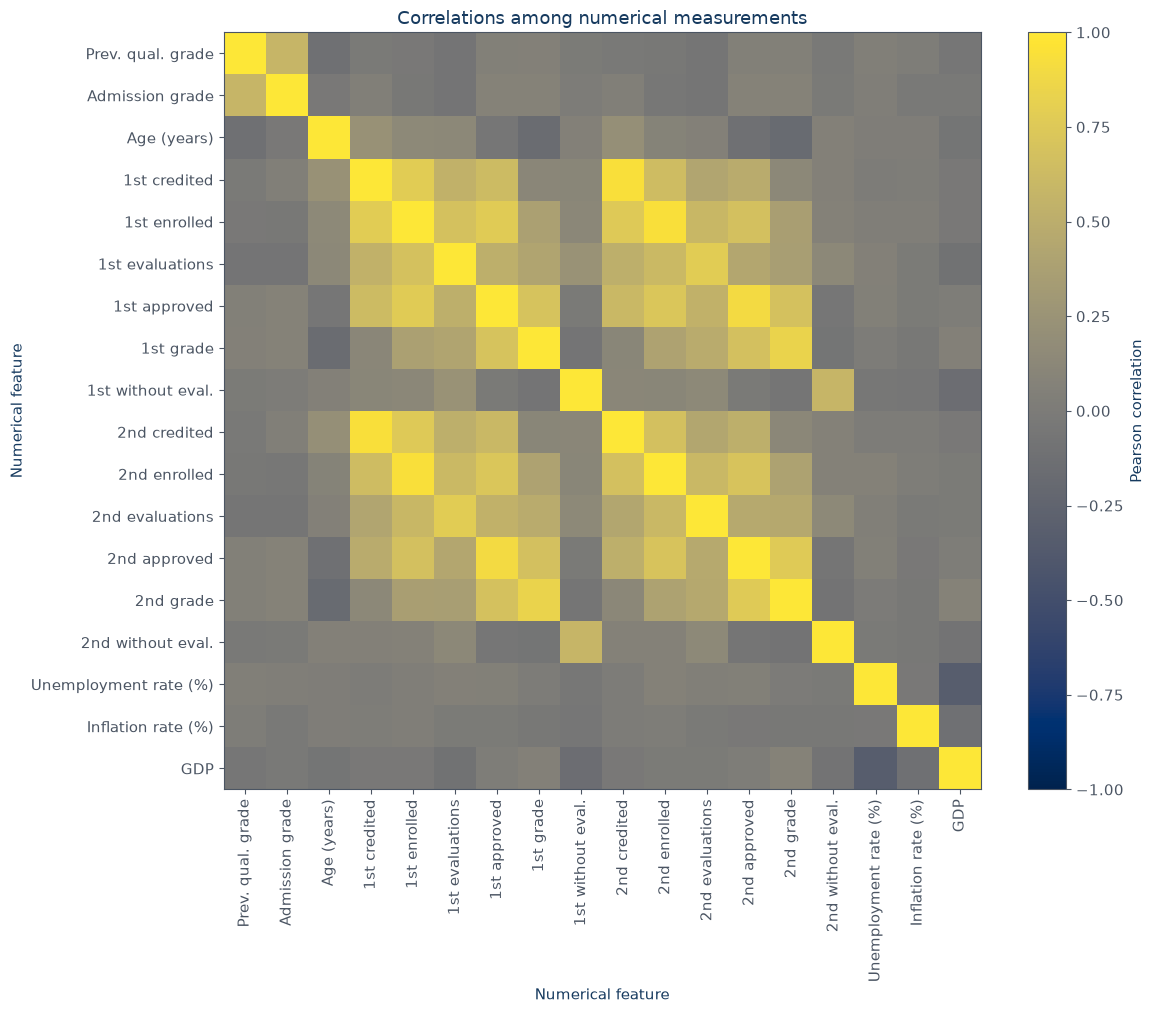

Label key:
Prev. qual. grade: Previous qualification (grade)
Admission grade: Admission grade
Age (years): Age at enrollment
1st credited: Curricular units 1st sem (credited)
1st enrolled: Curricular units 1st sem (enrolled)
1st evaluations: Curricular units 1st sem (evaluations)
1st approved: Curricular units 1st sem (approved)
1st grade: Curricular units 1st sem (grade)
1st without eval.: Curricular units 1st sem (without evaluations)
2nd credited: Curricular units 2nd sem (credited)
2nd enrolled: Curricular units 2nd sem (enrolled)
2nd evaluations: Curricular units 2nd sem (evaluations)
2nd approved: Curricular units 2nd sem (approved)
2nd grade: Curricular units 2nd sem (grade)
2nd without eval.: Curricular units 2nd sem (without evaluations)
Unemployment rate (%): Unemployment rate
Inflation rate (%): Inflation rate
GDP: GDP
Strongest absolute correlations:
0.945 | Curricular units 1st sem (credited) | Curricular units 2nd sem (credited)
0.943 | Curricular units 1st sem (enrolled)

In [12]:
short_labels = {
    "Previous qualification (grade)": "Prev. qual. grade",
    "Admission grade": "Admission grade",
    "Age at enrollment": "Age (years)",
    "Curricular units 1st sem (credited)": "1st credited",
    "Curricular units 1st sem (enrolled)": "1st enrolled",
    "Curricular units 1st sem (evaluations)": "1st evaluations",
    "Curricular units 1st sem (approved)": "1st approved",
    "Curricular units 1st sem (grade)": "1st grade",
    "Curricular units 1st sem (without evaluations)": "1st without eval.",
    "Curricular units 2nd sem (credited)": "2nd credited",
    "Curricular units 2nd sem (enrolled)": "2nd enrolled",
    "Curricular units 2nd sem (evaluations)": "2nd evaluations",
    "Curricular units 2nd sem (approved)": "2nd approved",
    "Curricular units 2nd sem (grade)": "2nd grade",
    "Curricular units 2nd sem (without evaluations)": "2nd without eval.",
    "Unemployment rate": "Unemployment rate (%)",
    "Inflation rate": "Inflation rate (%)",
    "GDP": "GDP",
}
correlation = df[NUMERICAL].corr()
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(correlation, cmap="cividis", vmin=-1, vmax=1)
cbar = fig.colorbar(image, ax=ax)
cbar.set_label("Pearson correlation")
labels = [short_labels[column] for column in NUMERICAL]
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90)
ax.set_yticklabels(labels)
ax.set_title("Correlations among numerical measurements")
ax.set_xlabel("Numerical feature")
ax.set_ylabel("Numerical feature")
fig.tight_layout()
figure_path = FIGURE_DIR / "figure_07_numerical_correlation_heatmap.png"
fig.savefig(figure_path, dpi=200)
plt.show()
print("Label key:")
for column, label in short_labels.items():
    print(f"{label}: {column}")

pairs = []
for i, left in enumerate(NUMERICAL):
    for right in NUMERICAL[i + 1:]:
        value = float(correlation.loc[left, right])
        pairs.append((abs(value), value, left, right))
pairs.sort(reverse=True)
print("Strongest absolute correlations:")
for _, value, left, right in pairs[:8]:
    print(f"{value:.3f} | {left} | {right}")
print("Admission grade with first-semester grade:", round(float(correlation.loc["Admission grade", "Curricular units 1st sem (grade)"]), 3))
print("Admission grade with second-semester grade:", round(float(correlation.loc["Admission grade", "Curricular units 2nd sem (grade)"]), 3))
print("Previous qualification grade with admission grade:", round(float(correlation.loc["Previous qualification (grade)", "Admission grade"]), 3))


### Correlation patterns

The strongest associations are between the same kind of count in semester 1 and semester 2. Credited units correlate at 0.945, enrolled units at 0.943, approved units at 0.904, grades at 0.837, and evaluations at 0.779. Students' first-semester record lines up closely with their second-semester record.

Approved units also move with grades in the same semester (0.696 in semester 1 and 0.761 in semester 2). That fits the earlier observation that a grade of 0 occurs together with zero approved units.

Entry grades tell a different story. Previous-qualification grade and admission grade correlate at 0.580. Admission grade correlates only 0.074 with each semester grade average. In this file, the grade a student arrives with is only weakly aligned with the semester average later recorded.

Unemployment, inflation, and GDP means barely differ by target. Mean unemployment is 11.616, 11.273, and 11.639. Their reference period is still unknown, and the similar group means do not make that dating problem disappear.


## 7. Unresolved data issues

These points were left open in the Phase 2 audit. This exploration does not resolve them.

- `Debtor` and `Tuition fees up to date` have no measurement date. Their associations with the target are large, and the date is still unknown.
- `Unemployment rate`, `Inflation rate`, and `GDP` have no reference date. Their values repeat across many students, and the class means are close.
- UCI's description of `Curricular units 2nd sem (without evaluations)` says the first semester, while the column name says the second semester. The column was not renamed and no rows were changed. Its median is 0 in every target class, so it does not separate the outcomes in this file.

The trailing tab in the daytime/evening header was removed only in this notebook's table. The raw file was not rewritten.


## 8. Implications for later preprocessing and modelling

No split, encoding, scaling, or model was fitted.

- The planned pair can still be used after this exploration. Logistic Regression remains a suitable interpretable baseline once category codes are encoded and numerical scales are handled. Random Forest remains a different model family that can represent non-linear splits. Neither result exists yet.
- Accuracy alone would be a poor summary because Graduate is about half the sample and Enrolled is the smallest class. The planned macro F1, precision, recall, balanced accuracy, and confusion matrix still match this imbalance.
- Integer category codes should be encoded as categories. They should not be scaled as if the code numbers were magnitudes.
- A grade of 0 needs an explicit preprocessing decision later, because it is tied exactly to zero approved units. This notebook does not impute or replace it.
- Debtor status and tuition status should not be treated as known at the prediction point until their dates are justified. The macroeconomic fields have the same timing problem.
- High-cardinality codes for course, nationality, and parental occupation will need a careful encoding choice. Rare marital-status codes should not be interpreted from their percentages alone.

The raw file was not modified.
